# P3-01. 대장내시경 용종 분할 ① 데이터·마스크 EDA + 분할 준비

## 프로젝트 3은 무엇이 다른가요?
| | 프로젝트 1 (분류) | 프로젝트 2 (검출) | **프로젝트 3 (분할)** |
|---|---|---|---|
| 모델의 답 | 사진 한 장에 라벨 하나 | 병변 위치에 **네모 박스** | 병변 모양 그대로 **픽셀마다** "용종이다/아니다" |
| 정답 형태 | 폴더 이름 | 좌표 4개 | **마스크 이미지** (사진과 같은 크기, 용종 = 흰색) |
| 모델 | ResNet 등 | YOLO | **U-Net** |
| 평가 | 정확도, AUROC | IoU, mAP | **Dice**, IoU |

## 데이터: Kvasir-SEG
- 대장내시경 사진 **1,000장** + 전문가가 용종 영역을 칠한 **마스크 1,000장** (노르웨이 공개 데이터)
- 크기가 작아서(약 46MB) **CPU만으로도 이 노트북 전체가 몇 분이면 끝나요** → YOLO 학습 중에 돌려도 부담이 적어요
- ⚠️ 이용 조건: **연구·교육 목적만** 가능, 결과를 발표하면 데이터 논문 인용 필요

**다운로드**
1. https://datasets.simula.no/kvasir-seg/ 에서 **Kvasir-SEG** 다운로드 링크 클릭 (보통 `kvasir-seg.zip`)
2. `medimg-study/data/raw/kvasir-seg/` 폴더를 만들고 zip을 그대로 넣기 → 1번 셀이 자동으로 풀어요

**이 노트북에서 답할 질문**
1. 마스크는 어떻게 생겼고, 정말 흑백 두 값(0/255)뿐인가?
2. 용종은 사진의 몇 %를 차지하나? 한 사진에 용종이 여러 개인 경우는?
3. 사진 크기는 제각각인가? 사진에 **용종 말고 다른 표시**(지름길 후보)가 있나?
4. 프로젝트 1처럼 **거의 같은 사진(같은 환자 연속 프레임)**이 있나? 있다면 어떻게 나눠야 누수가 없나?

> 실행 후 **2, 3, 4, 5, 6번 출력**을 Claude에게 보내주세요.

## 0. 준비 (GPU 안 씀)

In [1]:
import zipfile, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image
from tqdm.auto import tqdm
from scipy import ndimage
from sklearn.model_selection import GroupShuffleSplit

_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED)
RAW = Path("../../data/raw/kvasir-seg").resolve()
OUT = Path("../../outputs/p3").resolve(); OUT.mkdir(parents=True, exist_ok=True)
print("원본 폴더:", RAW, "| 존재:", RAW.exists())

d:\yerimlee\medimg-study\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


원본 폴더: D:\yerimlee\medimg-study\data\raw\kvasir-seg | 존재: True


## 1. 압축 풀기 + 파일 짝 맞추기

In [2]:
for z in RAW.glob("*.zip"):
    if not any(p.is_dir() for p in RAW.rglob("images")):
        print("압축 해제:", z.name)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(RAW)

IMG_DIR = next(p for p in RAW.rglob("images") if p.is_dir())
MSK_DIR = next(p for p in RAW.rglob("masks") if p.is_dir())
imgs = sorted(IMG_DIR.glob("*.jpg"))
pairs = [(p, MSK_DIR / p.name) for p in imgs if (MSK_DIR / p.name).exists()]
print(f"사진 {len(imgs)}장 / 마스크와 짝이 맞는 사진 {len(pairs)}장")
print("폴더:", IMG_DIR.relative_to(RAW), "/", MSK_DIR.relative_to(RAW))

압축 해제: kvasir-seg.zip
사진 1000장 / 마스크와 짝이 맞는 사진 1000장
폴더: Kvasir-SEG\images / Kvasir-SEG\masks


## 2. 마스크 들여다보기

> 🎯 **왜 하나요?** 분할 모델의 정답은 **마스크 이미지**예요. 용종 픽셀 = 흰색(255), 배경 = 검은색(0)이어야 해요.  
> 그런데 이 데이터의 마스크는 **JPG로 저장**돼 있어요. JPG는 압축할 때 경계가 살짝 뭉개져서 **0과 255 사이의 중간값**(회색)이 생겨요.  
> 정답에 회색이 섞이면 "이 픽셀은 반쯤 용종"이라는 이상한 정답이 되니까, **기준값 128로 잘라 0/1로 확실히 나눠야**(이진화) 해요. 실제로 그런지 확인해요.

마스크 크기 (529, 622), 서로 다른 값 18개
0도 255도 아닌 중간값 픽셀 비율: 1.03%


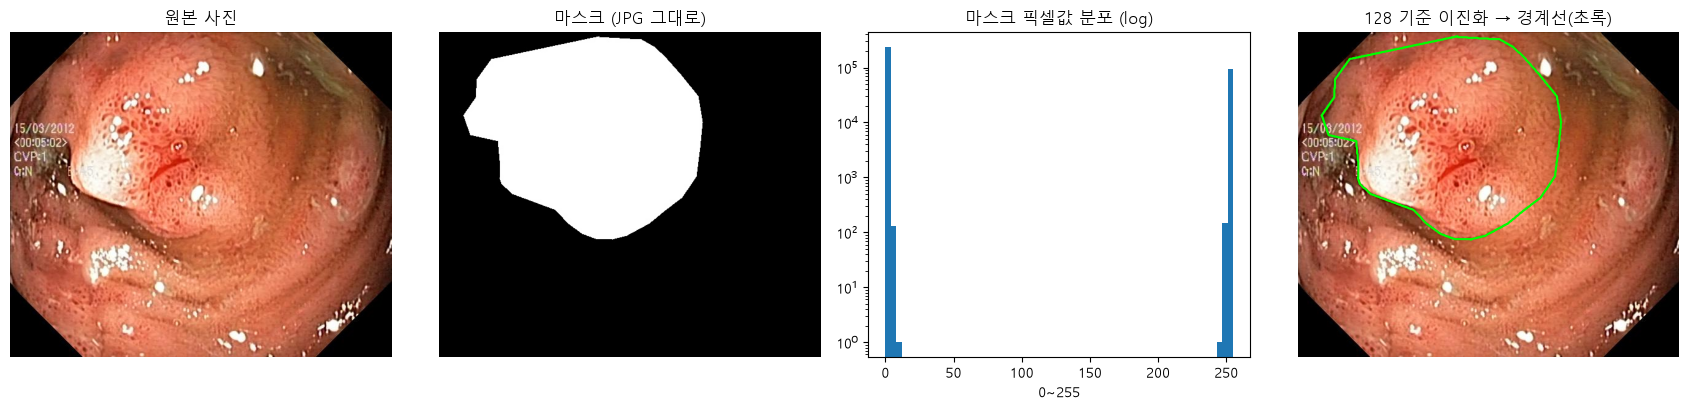

In [3]:
p_img, p_msk = pairs[0]
m = np.asarray(Image.open(p_msk).convert("L"))
vals, cnts = np.unique(m, return_counts=True)
print(f"마스크 크기 {m.shape}, 서로 다른 값 {len(vals)}개")
print("0도 255도 아닌 중간값 픽셀 비율:", f"{cnts[(vals > 0) & (vals < 255)].sum() / m.size:.2%}")

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
axes[0].imshow(Image.open(p_img)); axes[0].set_title("원본 사진")
axes[1].imshow(m, cmap="gray"); axes[1].set_title("마스크 (JPG 그대로)")
axes[2].hist(m.ravel(), bins=64, log=True); axes[2].set_title("마스크 픽셀값 분포 (log)"); axes[2].set_xlabel("0~255")
axes[3].imshow(Image.open(p_img)); axes[3].contour(m > 127, colors="lime", linewidths=1.5); axes[3].set_title("128 기준 이진화 → 경계선(초록)")
for a in [axes[0], axes[1], axes[3]]: a.axis("off")
plt.tight_layout(); plt.show()

## 3. 전체 통계: 사진 크기, 용종 면적, 용종 개수

> 🎯 **왜 하나요?**
> - **사진 크기**가 제각각이면 모델에 넣기 전에 통일해야 해요 (프로젝트 1과 같은 문제)
> - **용종 면적 비율**: 프로젝트 2의 박스 면적처럼, 작은 용종이 많으면 해상도를 높여야 하고 평가도 어려워져요
> - **용종 개수**: 한 마스크 안에 떨어진 덩어리가 몇 개인지 (`scipy.ndimage.label`로 덩어리 세기)

통계 계산: 100%|██████████| 1000/1000 [00:23<00:00, 42.92it/s]


사진 크기 Top 5:
622×530    78
626×547    66
626×546    61
622×529    56
622×528    53

가로 332~1920, 세로 352~1072

용종 면적 비율: 중앙값 11.4%, 최소 0.47%, 최대 81.2%

마스크 안 용종 덩어리 개수:
n_polyps
1     819
2     164
3      14
4       2
10      1


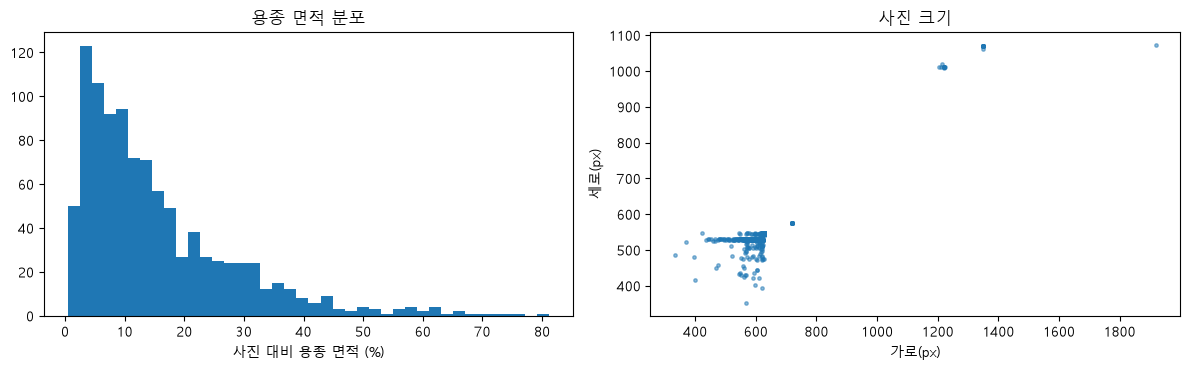

In [4]:
rows = []
for pi, pm in tqdm(pairs, desc="통계 계산"):
    with Image.open(pi) as im:
        w, h = im.size
    mb = np.asarray(Image.open(pm).convert("L")) > 127
    lab, n = ndimage.label(mb)
    rows.append({"file": pi.name, "w": w, "h": h, "area_ratio": mb.mean(), "n_polyps": n})
st = pd.DataFrame(rows)

print("사진 크기 Top 5:"); print((st["w"].astype(str) + "×" + st["h"].astype(str)).value_counts().head().to_string())
print(f"\n가로 {st['w'].min()}~{st['w'].max()}, 세로 {st['h'].min()}~{st['h'].max()}")
print(f"\n용종 면적 비율: 중앙값 {st['area_ratio'].median():.1%}, 최소 {st['area_ratio'].min():.2%}, 최대 {st['area_ratio'].max():.1%}")
print("\n마스크 안 용종 덩어리 개수:"); print(st["n_polyps"].value_counts().sort_index().to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(st["area_ratio"] * 100, bins=40); axes[0].set_xlabel("사진 대비 용종 면적 (%)"); axes[0].set_title("용종 면적 분포")
axes[1].scatter(st["w"], st["h"], s=6, alpha=.5); axes[1].set_xlabel("가로(px)"); axes[1].set_ylabel("세로(px)"); axes[1].set_title("사진 크기")
plt.tight_layout(); plt.show()

## 4. 예시 사진 + 마스크 겹쳐 보기

> 🎯 **보면서 확인할 것** (프로젝트 1·2에서 배운 체크리스트)
> - 용종 크기가 다양한가? 작은 용종은 사람 눈에도 잘 보이나?
> - **용종 말고 사진에 들어간 것**: 테두리의 검은 영역, **왼쪽 아래 초록색/검은 네모**(내시경 위치 표시 장치 화면), 글자 등 → 모델이 이걸로 뭔가를 배우면 지름길
> - 사진이 흐리거나 빛 반사가 심한 경우

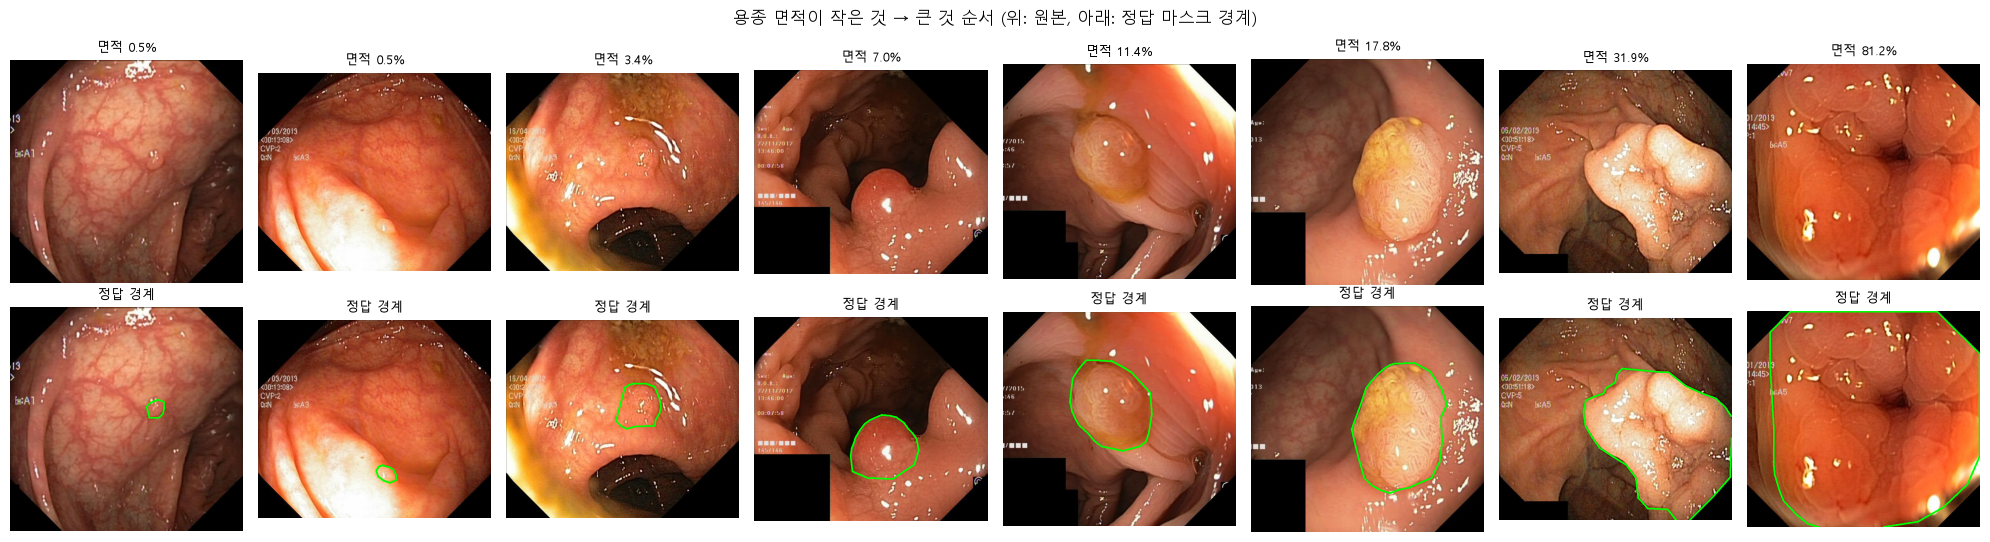

In [5]:
order = st.sort_values("area_ratio").index
n = len(order); picks = [order[int(q * (n - 1))] for q in [0, 0.002, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]]
fig, axes = plt.subplots(2, 8, figsize=(20, 5.6))
for k, i in enumerate(picks):
    pi, pm = pairs[i]
    im = Image.open(pi); mb = np.asarray(Image.open(pm).convert("L")) > 127
    axes[0, k].imshow(im); axes[0, k].set_title(f"면적 {st.loc[i, 'area_ratio']:.1%}", fontsize=9)
    axes[1, k].imshow(im); axes[1, k].contour(mb, colors="lime", linewidths=1.2); axes[1, k].set_title("정답 경계", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.suptitle("용종 면적이 작은 것 → 큰 것 순서 (위: 원본, 아래: 정답 마스크 경계)"); plt.tight_layout(); plt.show()

## 5. 거의 같은 사진 찾기 (누수 방지) ⭐

> 🎯 **왜 하나요?** 이 데이터에도 **환자 ID가 없어요.** 그런데 내시경은 **동영상에서 프레임을 뽑아** 만든 경우가 많아서, *같은 환자·같은 용종을 몇 초 차이로 찍은 거의 같은 사진*이 섞여 있을 수 있어요.  
> 이런 사진이 train과 test에 나뉘면 프로젝트 1처럼 점수가 부풀려져요.  
> 프로젝트 1 노트북 1에서 쓴 방법(**16×16 해시로 후보 → 64×64 픽셀 비교로 확정 → 묶음으로 합치기**)을 그대로 써요.  
> 내시경 사진은 뇌 MRI보다 서로 덜 비슷해서 기준(`THRESH`)을 조금 넉넉하게 잡았어요. 묶인 쌍을 **눈으로 확인**하고 필요하면 조절하세요.

64×64: 100%|██████████| 1000/1000 [00:04<00:00, 242.18it/s]


거의 같은 사진 쌍: 3개 / 묶음에 얽힌 사진: 6장 / 묶음 수: 3개


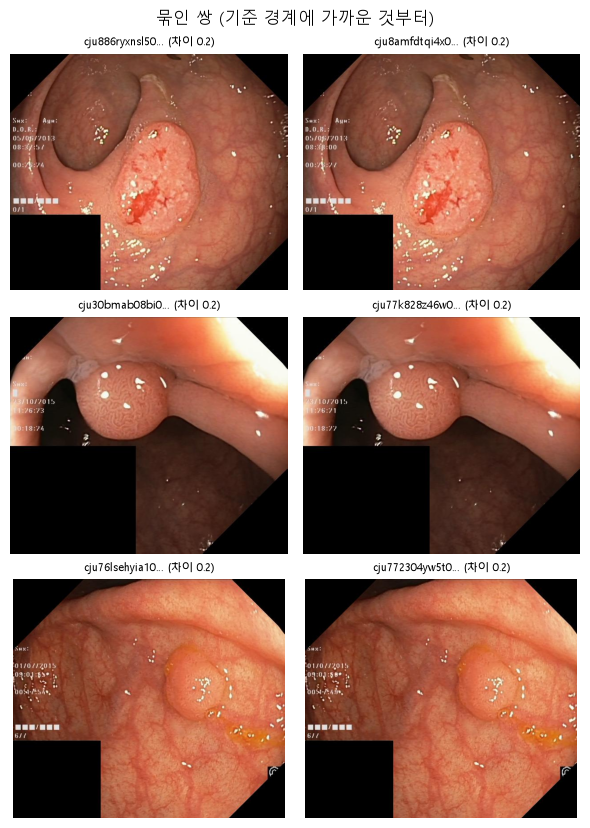

In [6]:
def gray_small(p, s):
    with Image.open(p) as im:
        return np.asarray(im.convert("L").resize((s, s), Image.BILINEAR), dtype=np.float32)

h16 = ["".join("1" if v else "0" for v in (g > g.mean()).ravel()) for g in (gray_small(p, 16) for p, _ in tqdm(pairs, desc="해시"))]
th64 = np.stack([gray_small(p, 64) for p, _ in tqdm(pairs, desc="64×64")])

THRESH = 12.0
idx_by_hash = pd.Series(range(len(pairs))).groupby(h16)
parent = list(range(len(pairs)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
pair_list = []
for _, g in idx_by_hash:
    g = list(g)
    for a in range(len(g)):
        for b in range(a + 1, len(g)):
            d = np.abs(th64[g[a]] - th64[g[b]]).mean()
            if d < THRESH:
                pair_list.append((g[a], g[b], d)); parent[find(g[a])] = find(g[b])
st["group"] = [find(i) for i in range(len(pairs))]
gsize = st["group"].map(st["group"].value_counts())
print(f"거의 같은 사진 쌍: {len(pair_list)}개 / 묶음에 얽힌 사진: {(gsize > 1).sum()}장 / 묶음 수: {st.loc[gsize > 1, 'group'].nunique()}개")

show = sorted(pair_list, key=lambda t: -t[2])[:5]          # 기준 경계에 가까운 쌍부터 확인
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(6, 2.8 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (a, b, d) in enumerate(show):
        for c, i in enumerate([a, b]):
            axes[r, c].imshow(Image.open(pairs[i][0])); axes[r, c].set_title(f"{pairs[i][0].name[:14]}… (차이 {d:.1f})", fontsize=8); axes[r, c].axis("off")
    plt.suptitle("묶인 쌍 (기준 경계에 가까운 것부터)"); plt.tight_layout(); plt.show()

## 6. 묶음 단위 train / val / test 분할 + 캐시 저장

> 🎯 **왜 묶음 단위?** 5번에서 같은 묶음으로 판정된 사진들은 **반드시 같은 split**에 들어가야 해요 (같은 환자는 한쪽에만 — 프로젝트 2의 환자 단위 분할과 같은 원리).  
> sklearn의 `GroupShuffleSplit`이 **그룹(묶음)을 쪼개지 않고** 나눠줘요. 비율은 80 : 10 : 10.
>
> 🎯 **캐시 저장**: 학습 노트북에서 매번 원본 JPG 1,000장을 다시 읽지 않도록, **256×256으로 줄인 사진·마스크를 파일 하나(.npz)**에 저장해요.  
> 디스크가 느린 환경에서도 학습 중 디스크를 거의 안 건드려서 **다른 작업(YOLO 학습)에 부담을 안 줘요.**  
> 사진은 bilinear로, **마스크는 nearest로** 줄여요 (마스크를 bilinear로 줄이면 경계에 다시 중간값이 생기니까요).

In [7]:
SIZE = 256
idx = np.arange(len(pairs))
g1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_i, tmp_i = next(g1.split(idx, groups=st["group"]))
g2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
va_r, te_r = next(g2.split(tmp_i, groups=st["group"].values[tmp_i]))
st["split"] = "train"; st.loc[tmp_i[va_r], "split"] = "val"; st.loc[tmp_i[te_r], "split"] = "test"
assert st.groupby("group")["split"].nunique().max() == 1
print("✅ 같은 묶음이 두 split에 걸치지 않음 확인")
print(st["split"].value_counts().to_string())

X = np.stack([np.asarray(Image.open(p).convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)) for p, _ in tqdm(pairs, desc="사진 리사이즈")])
Y = np.stack([(np.asarray(Image.open(m).convert("L").resize((SIZE, SIZE), Image.NEAREST)) > 127).astype(np.uint8) for _, m in tqdm(pairs, desc="마스크 리사이즈")])
np.savez_compressed(OUT / "kvasir_256.npz", X=X, Y=Y, split=st["split"].values, files=st["file"].values,
                    area_ratio=st["area_ratio"].values, n_polyps=st["n_polyps"].values)
st.to_csv(OUT / "kvasir_meta.csv", index=False, encoding="utf-8-sig")
print(f"\n저장: {OUT / 'kvasir_256.npz'}  (사진 {X.shape}, 마스크 {Y.shape}, 마스크 값 {np.unique(Y)})")

✅ 같은 묶음이 두 split에 걸치지 않음 확인
split
train    800
val      100
test     100


마스크 리사이즈: 100%|██████████| 1000/1000 [00:03<00:00, 324.58it/s]



저장: D:\yerimlee\medimg-study\outputs\p3\kvasir_256.npz  (사진 (1000, 256, 256, 3), 마스크 (1000, 256, 256), 마스크 값 [0 1])


## ✍️ 정리 & 생각해볼 질문

1. JPG 마스크에 중간값이 얼마나 있었나? 이진화를 안 했다면 어떤 문제가 생겼을까?
2. 용종 면적 비율의 중앙값은? 아주 작은 용종(1% 미만)은 몇 장쯤? 이런 용종은 256×256으로 줄여도 보일까?
3. 사진에 용종 말고 들어간 것(초록 네모, 검은 테두리 등)이 있었나? 분할 모델에도 지름길이 될 수 있을까? (힌트: 분할은 "어디가 용종인지"를 픽셀로 맞혀야 해서 분류보다 지름길에 덜 취약할 수 있어요)
4. 거의 같은 사진 묶음이 있었나? 묶음 단위로 나누지 않았다면 어떤 일이 생겼을까?

**메모:**
- 
